# Mean-reversion strategy

This code lays the foundation for a mean-reversion strategy that only trades after unusually large price moves.

In [14]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

NOTEBOOK_FILE = globals().get("__vsc_ipynb_file__")
WORKSPACE_FOLDER = Path(NOTEBOOK_FILE).resolve().parents[1] if NOTEBOOK_FILE else Path.cwd()
sys.path.insert(0, str(WORKSPACE_FOLDER / "src"))

from backtest.evaluation import calc_key_figures, plot_key_figures

DATE_COL = "AsOfDate"
PRICES = pl.read_csv(WORKSPACE_FOLDER / "prices" / "example_prices.csv", try_parse_dates=True).rename({"dates": DATE_COL})
INSTRUMENTS = [c for c in PRICES.columns if c != DATE_COL]

### Strategy summarized
* Estimate the volatility of the assets at time $T$ from the last $N$ days:
    $$\sigma_{T,j} = \sqrt{\frac{1}{N}\sum_{k=T-N+1}^{T} r_{k,j}^2}$$

* Measure how unusual the move over the last $M$ days is:

    $$z_{T,j} = \frac{P_{T,j} - P_{T-M,j}}{\sigma_{T-M,j}\sqrt{M}}$$

    We use the volatility from before the move, $\sigma_{T-M,j}$, so that the move does not inflate its own yardstick. The factor $\sqrt{M}$ is there because the variance of a sum of independent daily returns grows with the number of days. If this forecast is correct, $z_{T,j}$ has a standard deviation of about 1.

* Calculate the signal, which only bets against moves larger than a threshold $\theta$:

    $$X_{T, j} = \begin{cases} -\text{sign}(z_{T,j}) & \text{if } |z_{T,j}| > \theta \\ 0 & \text{otherwise} \end{cases}$$

    Note that the signal for a given asset will be $\pm 1$ when we trade and 0 when we do not. With $\theta = 2$, we hold a position on about 5% of asset-days.

* Calculate the positions $\tilde X_{T,j}$ that would make each traded asset contribute approximately equal risk to the portfolio (ignoring correlations between assets):
    $$\tilde X_{T,j} = \frac{X_{T,j}}{\sigma_{T,j}}$$

* The returns from  these positions need to be calculated taking into account the two-day lag:
    $$R_T = \sum_j \tilde X_{T-2,j}\, r_{T,j}$$

* The next step is to calculate the portfolio risk from holding equally-risk-weighted positions, over the last $N_r$ days:
    $$\hat\sigma_T = \text{std}\left(R_{T-N_r+1}, \dots, R_T\right)$$

    We use a much longer window than for the asset volatility, $N_r = 500$ instead of $N = 100$. Since the strategy rarely holds positions, a short window can contain very few trades. $\hat\sigma_T$ then collapses towards 0, which makes the next position enormous.

* We can then calculate the final portfolio positions as:
    $$\hat X_{T,j} = \frac{\tilde X_{T,j}}{\hat\sigma_T}$$

    Dividing by $\sigma_{T,j}$ balances risk between assets, and dividing by $\hat\sigma_T$ scales the risk of the whole strategy. Defining the risk of an asset as the size of our position multiplied by its volatility, and using $|X_{T,j}| = 1$ for an asset we trade:

    $$\text{risk}_{T+2,j} = \sigma^{\text{true}}_{T+2,j} \cdot |\hat X_{T,j}| = \sigma^{\text{true}}_{T+2,j} \cdot \frac{|X_{T,j}|}{\sigma_{T,j}\,\hat\sigma_T} \approx \frac{1}{\hat\sigma_T}$$

    Every asset we trade therefore carries about the same risk, $1/\hat\sigma_T$, and every other asset carries none.

* The realized return from the portfolio will be:

    $$\hat R_{T+2} = \sum_j \hat X_{T,j}\, r_{T+2,j} = \frac{1}{\hat\sigma_T}\sum_j \tilde X_{T,j}\, r_{T+2,j} = \frac{R_{T+2}}{\hat\sigma_T}$$

    Let $\sigma^{\text{true}}_{T+2}$ be the true, unobserved volatility of $R_{T+2}$, given the data through day $T$. Since $\hat\sigma_T$ is known on day $T$, it acts as a constant:

    $$\text{Var}\left(\hat R_{T+2} \mid \text{data through } T\right) = \frac{\text{Var}\left(R_{T+2} \mid \text{data through } T\right)}{\hat\sigma_T^2} = \frac{\left(\sigma^{\text{true}}_{T+2}\right)^2}{\hat\sigma_T^2}$$

    Unlike a strategy that always holds positions, this does not stay close to 1 from day to day. $\sigma^{\text{true}}_{T+2}$ is 0 when we hold nothing and larger when several assets trigger at once. The final return therefore only has a standard deviation of about 1 on average over time, provided $\hat\sigma_T$ is a good estimate of the strategy's average risk. Returns are concentrated on the days we trade, which makes them fat-tailed.

* The mean-reversion comes from betting against unusually large moves. We go short if the price has risen unusually far and long if it has fallen unusually far, so the return on asset $j$ when we trade is:

    $$\hat X_{T,j}\, r_{T+2,j} = \frac{-\text{sign}(z_{T,j})\, r_{T+2,j}}{\sigma_{T,j}\,\hat\sigma_T}$$

    This is positive when the return on day $T+2$ goes against the large move, and negative when it has the same sign. The strategy therefore makes money on average if:

    $$E\left[-\text{sign}(z_{T,j})\, r_{T+2,j} \,\middle|\, |z_{T,j}| > \theta\right] > 0$$

    This requires large moves to partly reverse, for example because they overshoot after forced selling or an overreaction. On the example data we did not find this: for $M$ from 1 to 20 days and $\theta$ from 1 to 3, none of the combinations showed a statistically significant reversal two days after the move.

* Trading incurs a transaction cost proportional to the size of each order. As calculated in `evaluation.py`, the net return of the strategy is:

    $$\hat R^{\text{net}}_T = \sum_j \left[\hat X_{T-2,j}\, r_{T,j} - c\, s_{T,j} \left|\hat X_{T-2,j} - \hat X_{T-3,j}\right|\right]$$

    Here $c = 0.02$, and $s_{T,j}$ is the rolling 100-day standard deviation of the daily returns of asset $j$, using data through day $T-1$. This net return is what the Adjusted Sharpe Ratio is evaluated on.

    Costs arise in two ways. The largest orders come from entering and leaving a trade, when $X_{T,j}$ changes between 0 and $\pm 1$, while smaller orders occur as $\sigma_{T,j}$ and $\hat\sigma_T$ change during a trade. Entering and leaving costs about $2c = 0.04$ daily standard deviations, so the average reversal has to be larger than that. A higher $\theta$ trades less often and reduces total costs, but leaves fewer trades and more fat-tailed returns.




In [15]:
def calc_positions(M, threshold, prices, N=100, N_risk=500):
    """
    Calculate the final positions of the mean-reversion strategy.

    Parameters:
    M (int): The length of the move we measure, in days.
    threshold (float): How large the move must be to trade, in standard deviations.
    prices (pl.DataFrame): DataFrame containing a date column and one price column per instrument.
    N (int): The window for the volatility estimate, in days.
    N_risk (int): The window for the portfolio risk estimate, in days.

    Returns:
    pl.DataFrame: The date column and the final position of each instrument. Positions are null
    until there is enough data for all windows, and 0 when the strategy is not trading.
    """
    instruments = [c for c in prices.columns if c != DATE_COL]
    returns = prices.select(pl.col(instruments).diff())

    # Asset volatility: sigma_T = sqrt(mean of r^2 over the last N days)
    sigma = returns.select(pl.col(instruments).pow(2).rolling_mean(N).sqrt())

    # Size of the move: z_T = (P_T - P_{T-M}) / (sigma_{T-M} * sqrt(M))
    z = prices.select(pl.col(instruments).diff(M)) / sigma.select(pl.all().shift(M) * M**0.5)

    # Signal: X_T = -sign(z_T) if |z_T| > threshold, otherwise 0
    X = z.select(-pl.all().sign() * (pl.all().abs() > threshold).cast(pl.Float64))

    # Equal-risk positions: X_tilde_T = X_T / sigma_T
    X_tilde = X / sigma

    # Portfolio return with the two-day lag: R_T = sum over j of X_tilde_{T-2} * r_T
    asset_returns = X_tilde.select(pl.all().shift(2)) * returns
    R = asset_returns.select(
        pl.when(pl.all_horizontal(pl.all().is_null()))
        .then(None)
        .otherwise(pl.sum_horizontal(pl.all()))
        .alias("R")
    )["R"]

    # Portfolio risk: sigma_hat_T = std of R over the last N_risk days
    # If nothing was traded in the window the risk is 0, so we hold no position (null)
    sigma_hat = R.rolling_std(N_risk).to_frame("risk").select(
        pl.when(pl.col("risk") > 0).then(pl.col("risk")).alias("risk")
    )["risk"]

    # Final positions: X_hat_T = X_tilde_T / sigma_hat_T
    X_hat = X_tilde.select(pl.all() / sigma_hat).fill_nan(None)

    return X_hat.with_columns(prices[DATE_COL]).select(DATE_COL, *instruments)


positions = calc_positions(5, 2.0, PRICES)

### Evaluation
We evaluate the positions with the tools in `evaluation.py`, including its approximation of transaction costs (slippage).

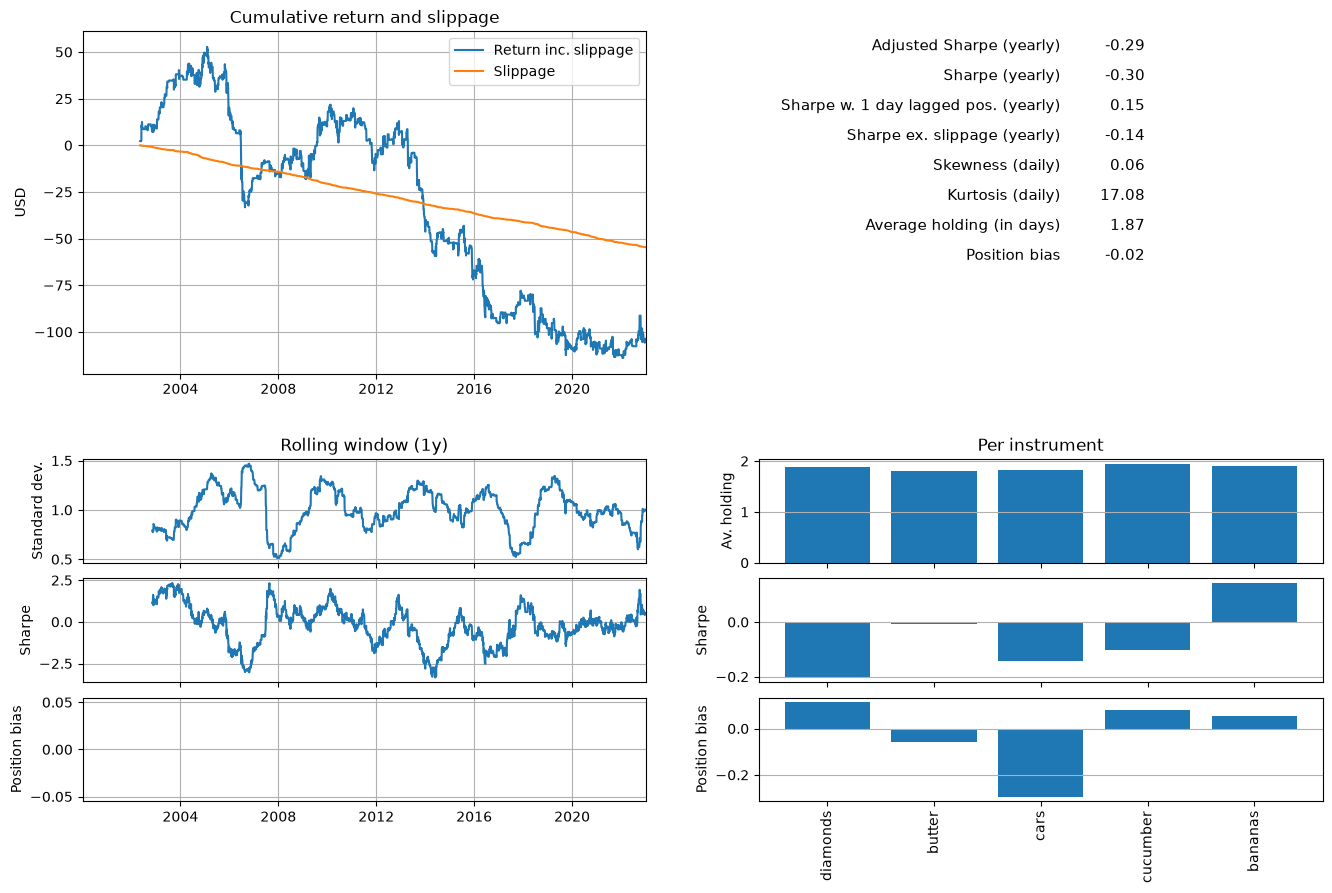

In [16]:
plot_key_figures(positions, PRICES)

#### Key figures
The default key figures as a dict. See the documentation in `evaluation.py` for what each one means.

In [17]:
calc_key_figures(positions, PRICES)

{'sharpe': -0.30448288207509533,
 'sharpe_1d_lag': 0.15000810405442971,
 'av_holding': 1.8728810299729195,
 'position_bias': -0.020486486734033783,
 'skewness': 0.06004434237694288,
 'kurtosis': 17.08446934986428,
 'adjusted_sharpe': -0.2869890896710633}

#### Cost sensitivity
How the Sharpe ratio changes with the cost coefficient. The default in `evaluation.py` is `costs=-0.02`.

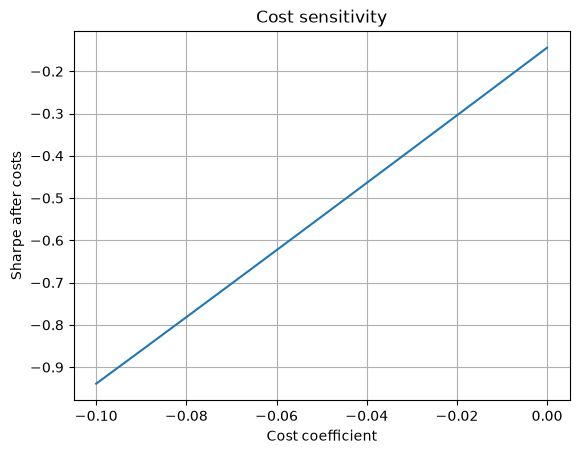

In [18]:
cost_coeffs = np.linspace(0, -0.1, 10)
sharpe_per_cost_coef = [
    calc_key_figures(positions, PRICES, costs=float(cost), key_figures=["sharpe"])["sharpe"]
    for cost in cost_coeffs
]
fig, ax = plt.subplots()
ax.plot(cost_coeffs, sharpe_per_cost_coef)
ax.set_title("Cost sensitivity")
ax.set_ylabel("Sharpe after costs")
ax.set_xlabel("Cost coefficient")
ax.grid()

### Leakage test
Positions on day $T$ may only use data up to and including day $T$. We test this in the two ways described in the instructions: by using a shorter history, and by changing the prices after day $T$. In both cases, the positions up to day $T$ must stay identical.

In [19]:
def check_no_leakage(position_func, prices, days_removed=20):
    """
    Raise an AssertionError if the positions from position_func depend on future data.

    Parameters:
    position_func (callable): Takes a prices DataFrame and returns a positions DataFrame.
    prices (pl.DataFrame): DataFrame containing a date column and one price column per instrument.
    days_removed (int): The number of days to remove in the shorter-history test.
    """
    instruments = [c for c in prices.columns if c != DATE_COL]
    full = position_func(prices)

    # Test 1: positions from a shorter history must equal those from the full history
    truncated = position_func(prices.head(prices.height - days_removed))
    assert truncated.equals(full.head(truncated.height)), "Leakage: shorter history changes earlier positions"

    # Test 2: changing prices after day T must not change positions up to and including day T
    T = prices.height // 2
    is_future = pl.int_range(pl.len()) > T
    altered = prices.with_columns(
        pl.when(is_future).then(pl.col(c) * 1.5 + 100).otherwise(pl.col(c)).alias(c) for c in instruments
    )
    assert position_func(altered).head(T + 1).equals(full.head(T + 1)), "Leakage: future prices change earlier positions"


check_no_leakage(lambda prices: calc_positions(5, 2.0, prices), PRICES)
print("Leakage tests passed")

Leakage tests passed
